# Magneto-Optical Kerr and Faraday Effect

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/06-light/01-magneto_optics.ipynb)

In this example the magneto-optical Kerr effect (MOKE) and the Faraday effect of a thin magnetic film are calculated for visible light with the multilayer formalisms of the {py:mod}`scattering <udkm1Dsim.simulations.scattering>` package, see the [example of the multilayer formalisms](#example_multilayer_formalisms).
The magnetization rotates and elliptically polarizes the reflected and transmitted light, which is described by the gyrotropic, off-diagonal part of the dielectric tensor.
Following {cite:t}`mansuripur2000`, the dielectric tensor of a TbFeCo film at 633 nm is used.

:::{admonition} Reference {cite}`mansuripur2000`
:class: seealso
M. Mansuripur, *The Magneto-Optical Kerr Effect*, [Opt. Photonics News 11(10), 34 (2000)](http://www.doi.org/10.1364/OPN.11.10.000034)
:::

## Setup

Do all necessary imports and settings.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim
    import udkm1Dsim as ud

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

## Structure

Refer to the [structure example](#example_structure) for more details.

The free-standing TbFeCo film is a single homogeneous {py:class}`Layer <udkm1Dsim.structures.layers.Layer>` in vacuum.
Its dielectric tensor for a magnetization $\mathbf{m}$ along the surface normal $z$ is

$$
\varepsilon = \begin{pmatrix}
\varepsilon_{xx} & \varepsilon_{xy} & 0 \\
-\varepsilon_{xy} & \varepsilon_{xx} & 0 \\
0 & 0 & \varepsilon_{xx}
\end{pmatrix}
$$

with $\varepsilon_{xx} = -8 + 27i$ and $\varepsilon_{xy} = -0.6 + 0.2i$ from Fig. 2 of {cite:t}`mansuripur2000`.
The {py:class}`Dielectric <udkm1Dsim.structures.dielectric.Dielectric>` holds the non-magnetic part $\varepsilon^0 = \varepsilon_{xx}$ and the gyrotropic part $\varepsilon^m$, which is rotated with the magnetization by $\varepsilon_{ij} = \varepsilon^0 \delta_{ij} - i \varepsilon^m \epsilon_{ijk} m_k$.
Hence, the gyrotropic part is $\varepsilon^m = i \varepsilon_{xy}$.
Both are given as constants, which are independent of the photon energy.

In [2]:
eps_xx = -8 + 27j
eps_xy = -0.6 + 0.2j

layer_TbFeCo = ud.Layer(
    "TbFeCo",
    "TbFeCo",
    structural=ud.StructuralParameters(thickness=20 * u.nm, density=8000 * u.kg / u.m**3),
    optical=ud.OpticalParameters(
        dielectric=ud.Dielectric(
            eps0=ud.Dispersion.from_array(None, eps_xx),
            eps_mag=ud.Dispersion.from_array(None, 1j * eps_xy),
        )
    ),
    magnetic=ud.MagneticParameters(magnetization=(0, 0, 1)),
)
layer_TbFeCo.get_dielectric_tensor(633 * u.nm)[0]

array([[-8. +27.j , -0.6 +0.2j,  0.  +0.j ],
       [ 0.6 -0.2j, -8. +27.j ,  0.  +0.j ],
       [ 0.  +0.j ,  0.  +0.j , -8. +27.j ]])

The vacuum below the film is the substrate without any thickness.

In [3]:
S = ud.Structure("TbFeCo film")
S.add_sub_structure(layer_TbFeCo, 1)
S.add_substrate(ud.Vacuum(thickness=0 * u.nm))
S

times,sub-structure,thickness
1,TbFeCo,20 nm


## Polar Kerr and Faraday Effect

The exact eigenmodes of the {py:class}`BerremanStepanov <udkm1Dsim.simulations.scattering.berreman.BerremanStepanov>` formalism are used as reference.
At normal incidence, i.e. a grazing angle of $\theta = 90°$, the Jones matrices of the reflected and transmitted light are calculated for different thicknesses of the film.
The rotation and ellipticity of the polarization ellipse of the reflected and transmitted light for an incoming $\sigma$ polarization are the Kerr and Faraday angles, see {py:meth}`calc_kerr_angles <udkm1Dsim.simulations.scattering.multilayer.MultilayerScattering.calc_kerr_angles>`.

In [4]:
bs = ud.BerremanStepanov(S, True)
bs.save_data = False
bs.disp_messages = False
bs.wl = np.r_[633] * u.nm
bs.theta = np.r_[90] * u.deg
bs

incoming polarizations set to: sigma
analyzer polarizations set to: unpolarized


parameter,value
force recalc,True
cache directory,./
display messages,False
save data,False
progress bar,True
energy,1.959 eV
wavelength,633 nm
wavenumber,0.009926 1/nm
theta,[90] deg
q_z,[0.01985] 1/nm


In [5]:
thicknesses = np.r_[1:100:0.5] * u.nm
kerr = np.zeros([len(thicknesses), 2])
faraday = np.zeros([len(thicknesses), 2])
eigenvalues = np.zeros([len(thicknesses), 2], dtype=complex)

for i, thickness in enumerate(thicknesses):
    layer_TbFeCo.structural.thickness = thickness
    R, R_phi, T, T_phi = bs.homogeneous_jones_matrices()
    kerr[i, :] = [angle.m_as("deg").item() for angle in bs.calc_kerr_angles(R)]
    faraday[i, :] = [angle.m_as("deg").item() for angle in bs.calc_kerr_angles(T)]
    eigenvalues[i, :] = np.sort_complex(np.linalg.eigvals(T[0, 0]))

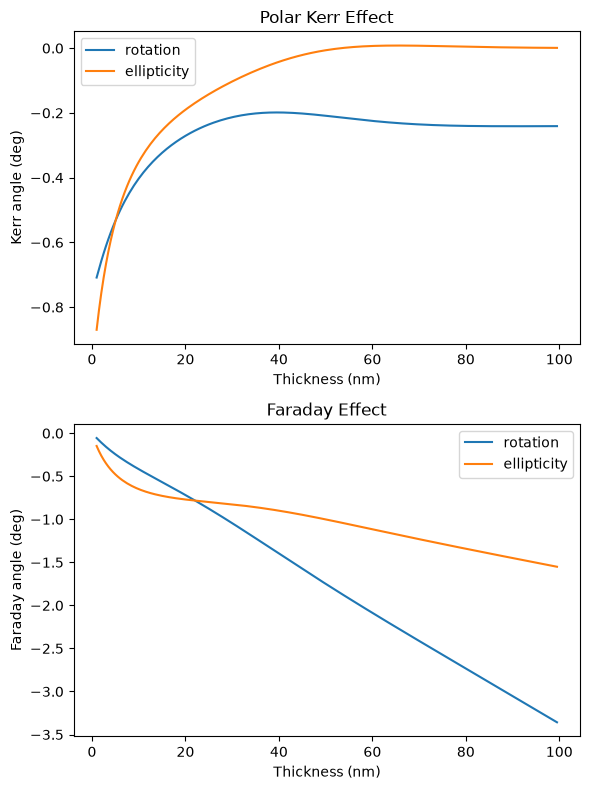

In [6]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
plt.plot(thicknesses, kerr[:, 0], label="rotation")
plt.plot(thicknesses, kerr[:, 1], label="ellipticity")
plt.xlabel("Thickness (nm)")
plt.ylabel("Kerr angle (deg)")
plt.legend()
plt.title("Polar Kerr Effect")

plt.subplot(2, 1, 2)
plt.plot(thicknesses, faraday[:, 0], label="rotation")
plt.plot(thicknesses, faraday[:, 1], label="ellipticity")
plt.xlabel("Thickness (nm)")
plt.ylabel("Faraday angle (deg)")
plt.legend()
plt.title("Faraday Effect")

plt.tight_layout()
plt.show()

The Kerr angles saturate for films thicker than the penetration depth of about 20 nm, while the Faraday rotation grows with the thickness, but the transmitted intensity decays exponentially.

At normal incidence, the circularly polarized modes with the refractive indices $n_\pm = \sqrt{\varepsilon_{xx} \pm i \varepsilon_{xy}}$ propagate independently through the film.
Hence, the eigenvalues of the Jones matrix of the transmission equal the transmission of a slab with the refractive index $n_\pm$ including all multiple reflections

$$
t_\pm = \frac{(1 - r_\pm^2) e^{i k n_\pm d}}{1 - r_\pm^2 e^{2 i k n_\pm d}}, \quad r_\pm = \frac{1 - n_\pm}{1 + n_\pm}
$$

which serves as an analytical check of the formalism.

largest deviation: 6.7e-16


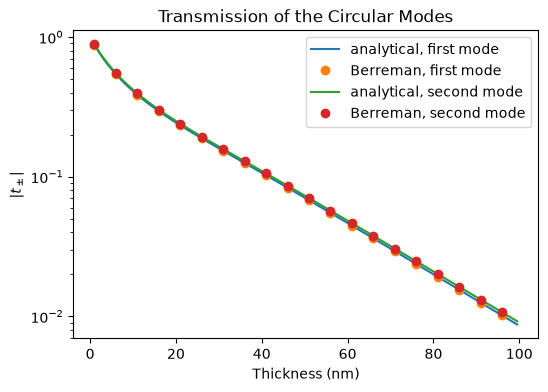

In [7]:
k = 2 * np.pi / (633 * u.nm)
t_circular = np.zeros_like(eigenvalues)
for j, n in enumerate([np.sqrt(eps_xx + 1j * eps_xy), np.sqrt(eps_xx - 1j * eps_xy)]):
    r = (1 - n) / (1 + n)
    phase = np.exp(1j * (k * n * thicknesses).m_as(""))
    t_circular[:, j] = (1 - r**2) * phase / (1 - r**2 * phase**2)
t_circular = np.sort_complex(t_circular)

print(f"largest deviation: {np.max(np.abs(eigenvalues - t_circular)):.1e}")

plt.figure(figsize=[6, 4])
for j, label in enumerate(["first", "second"]):
    plt.semilogy(thicknesses, np.abs(t_circular[:, j]), label=f"analytical, {label} mode")
    plt.semilogy(
        thicknesses[::10], np.abs(eigenvalues[::10, j]), "o", label=f"Berreman, {label} mode"
    )
plt.xlabel("Thickness (nm)")
plt.ylabel(r"$|t_\pm|$")
plt.legend()
plt.title("Transmission of the Circular Modes")
plt.show()

## Kerr Geometries

The Kerr effect depends on the direction of the magnetization relative to the plane of incidence $yz$:

- **polar**: along the surface normal $z$,
- **longitudinal**: in the film plane and in the plane of incidence along $y$,
- **transverse**: in the film plane and perpendicular to the plane of incidence along $x$.

The polar and longitudinal magnetization rotate the polarization, while the transverse magnetization only changes the reflectivity of $\pi$ polarized light.
Hence, the latter is given as asymmetry $(R^+ - R^-)/(R^+ + R^-)$ of the reflectivities for the opposite magnetizations.
The incidence angle is scanned for the 20 nm thick film and compared for the formalisms with exact and analytical eigenmodes.

In [8]:
layer_TbFeCo.structural.thickness = 20 * u.nm
theta = np.r_[1:90:0.5] * u.deg
geometries = {"polar": (0, 0, 1), "longitudinal": (0, 1, 0), "transverse": (1, 0, 0)}

results = {}
for formalism in [ud.BerremanStepanov, ud.Elzo]:
    sim = formalism(S, True, save_data=False, disp_messages=False)
    sim.wl = np.r_[633] * u.nm
    sim.theta = theta
    sim.set_polarization("pi", "none")
    for geometry, magnetization in geometries.items():
        layer_TbFeCo.magnetization = magnetization
        R, R_phi, _, _ = sim.homogeneous_jones_matrices()
        R_pi, R_pi_phi, _, _ = sim.homogeneous_reflectivity()
        results[formalism.__name__, geometry] = {
            "kerr_s": sim.calc_kerr_angles(R)[0].m_as("deg")[0, :],
            "kerr_p": sim.calc_kerr_angles(R, pi_incident=True)[0].m_as("deg")[0, :],
            "asymmetry": ((R_pi - R_pi_phi) / (R_pi + R_pi_phi))[0, :],
        }

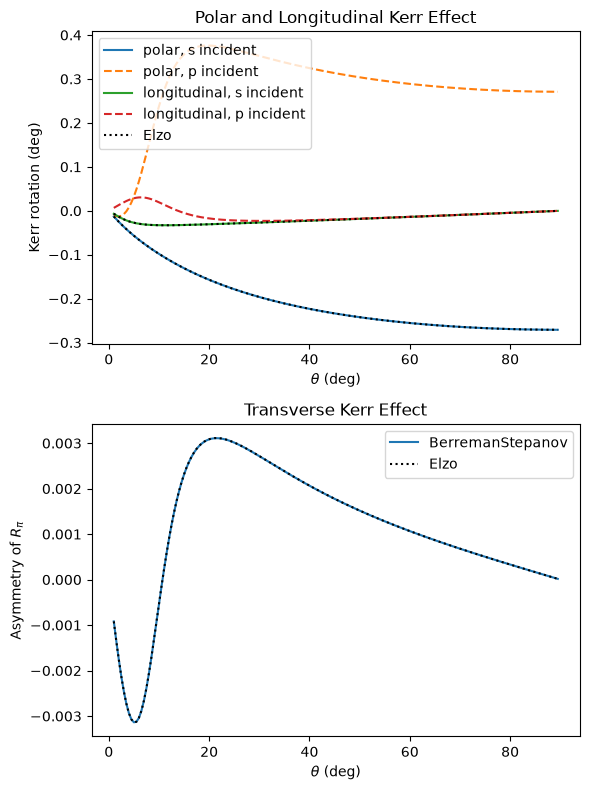

In [9]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
for geometry in ["polar", "longitudinal"]:
    for incidence, style in [("s", "-"), ("p", "--")]:
        plt.plot(
            theta,
            results["BerremanStepanov", geometry][f"kerr_{incidence}"],
            style,
            label=f"{geometry}, {incidence} incident",
        )
plt.plot(theta, results["Elzo", "polar"]["kerr_s"], "k:", label="Elzo")
plt.plot(theta, results["Elzo", "longitudinal"]["kerr_s"], "k:")
plt.xlabel(r"$\theta$ (deg)")
plt.ylabel("Kerr rotation (deg)")
plt.legend()
plt.title("Polar and Longitudinal Kerr Effect")

plt.subplot(2, 1, 2)
plt.plot(theta, results["BerremanStepanov", "transverse"]["asymmetry"], label="BerremanStepanov")
plt.plot(theta, results["Elzo", "transverse"]["asymmetry"], "k:", label="Elzo")
plt.xlabel(r"$\theta$ (deg)")
plt.ylabel(r"Asymmetry of $R_\pi$")
plt.legend()
plt.title("Transverse Kerr Effect")

plt.tight_layout()
plt.show()

The polar Kerr effect is largest at normal incidence, while the longitudinal and transverse Kerr effects vanish there, as the magnetization is perpendicular to the wave vector.
The opposite signs for $s$ and $p$ incident light at normal incidence stem from the Fresnel convention of the $\pi$ polarization with $r_{\pi\pi} = -r_{\sigma\sigma}$ at normal incidence.
The analytical eigenmodes of {py:class}`Elzo <udkm1Dsim.simulations.scattering.elzo.Elzo>` agree with the exact ones, as the gyrotropic part is small compared to the diagonal part of the dielectric tensor.